In [1]:
import pandas as pd


In [2]:
data = pd.read_csv("RT_IOT2022_preparado.csv")
data.head()

,puerto_destino,protocolo,servicio,duracion,ida_paquetes,vuelta_paquetes,ida_paquetes_con_datos,vuelta_paquetes_con_datos,ida_paquetes_por_seg,razon_vuelta_ida,...,activo_max,activo_total,activo_prom,activo_desv,inactivo_total,inactivo_desv,ida_ventana_inicial,vuelta_ventana_inicial,ida_ventana_final,tipo_ataque
0,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.555556,...,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.555556,...,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.555556,...,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.555556,...,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.555556,...,2.087657e+06,2.087657e+06,2.087657e+06,0.0,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [3]:
print(data.dtypes)

puerto_destino              int64
protocolo                     str
servicio                      str
duracion                  float64
ida_paquetes                int64
                           ...   
inactivo_desv             float64
ida_ventana_inicial         int64
vuelta_ventana_inicial      int64
ida_ventana_final           int64
tipo_ataque                   str
Length: 63, dtype: object


In [4]:
cols_int = data.select_dtypes(include="int").columns.tolist()
cols_int

['puerto_destino',
 'ida_paquetes',
 'vuelta_paquetes',
 'ida_paquetes_con_datos',
 'vuelta_paquetes_con_datos',
 'ida_cabecera_total',
 'ida_cabecera_min',
 'ida_cabecera_max',
 'vuelta_cabecera_min',
 'vuelta_cabecera_max',
 'bandera_FIN',
 'bandera_SYN',
 'bandera_RST',
 'ida_bandera_PSH',
 'vuelta_bandera_PSH',
 'bandera_ACK',
 'ida_bandera_URG',
 'ida_ventana_inicial',
 'vuelta_ventana_inicial',
 'ida_ventana_final']

In [5]:
cols_float = data.select_dtypes(include="float").columns.tolist()
cols_float

['duracion',
 'ida_paquetes_por_seg',
 'razon_vuelta_ida',
 'ida_carga_min',
 'ida_carga_max',
 'ida_carga_total',
 'ida_carga_prom',
 'ida_carga_desv',
 'vuelta_carga_min',
 'vuelta_carga_max',
 'vuelta_carga_total',
 'vuelta_carga_prom',
 'vuelta_carga_desv',
 'flujo_carga_min',
 'flujo_carga_prom',
 'flujo_carga_desv',
 'ida_intervalo_min',
 'ida_intervalo_max',
 'ida_intervalo_total',
 'ida_intervalo_prom',
 'ida_intervalo_desv',
 'vuelta_intervalo_min',
 'vuelta_intervalo_max',
 'vuelta_intervalo_total',
 'vuelta_intervalo_prom',
 'vuelta_intervalo_desv',
 'flujo_intervalo_min',
 'flujo_intervalo_max',
 'flujo_intervalo_total',
 'flujo_intervalo_prom',
 'flujo_intervalo_desv',
 'flujo_bytes_por_seg',
 'ida_subflujo_paquetes',
 'activo_min',
 'activo_max',
 'activo_total',
 'activo_prom',
 'activo_desv',
 'inactivo_total',
 'inactivo_desv']

In [6]:
cols_str = data.select_dtypes(include="object").columns.tolist()
cols_str

/tmp/ipykernel_49419/3928425202.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_str = data.select_dtypes(include="object").columns.tolist()


['protocolo', 'servicio', 'tipo_ataque']

In [7]:
data["protocolo"].value_counts()

protocolo
tcp     15293
udp      8497
icmp       32
Name: count, dtype: int64

In [8]:
pd.set_option("display.width", 250)

print(pd.crosstab(data["protocolo"], data["tipo_ataque"]))
print()
print(pd.crosstab(data["protocolo"], data["tipo_ataque"], normalize="index").round(2))

tipo_ataque  ARP_poisioning  DDOS_Slowloris  DOS_SYN_Hping  MQTT_Publish  Metasploit_Brute_Force_SSH  NMAP_FIN_SCAN  NMAP_OS_DETECTION  NMAP_TCP_scan  NMAP_UDP_SCAN  NMAP_XMAS_TREE_SCAN  Thing_Speak  Wipro_bulb
protocolo                                                                                                                                                                                                         
icmp                      6               0              0             0                           0              0                  0              0              2                    0           22           2
tcp                    1843             529             57          4141                          29              2               1899           1002            140                 1891         3604         156
udp                    3445               3              0             0                           6              3                  0              0       

In [9]:
data = pd.get_dummies(data, columns=["protocolo"], prefix="protocolo", dtype=int)

In [10]:
data.head()

,puerto_destino,servicio,duracion,ida_paquetes,vuelta_paquetes,ida_paquetes_con_datos,vuelta_paquetes_con_datos,ida_paquetes_por_seg,razon_vuelta_ida,ida_cabecera_total,...,activo_desv,inactivo_total,inactivo_desv,ida_ventana_inicial,vuelta_ventana_inicial,ida_ventana_final,tipo_ataque,protocolo_icmp,protocolo_tcp,protocolo_udp
0,1883,mqtt,32.011598,9,5,3,3,0.281148,0.555556,296,...,0.0,2.972918e+07,0.0,64240,26847,502,MQTT_Publish,0,1,0
1,1883,mqtt,31.883584,9,5,3,3,0.282277,0.555556,296,...,0.0,2.985528e+07,0.0,64240,26847,502,MQTT_Publish,0,1,0
2,1883,mqtt,32.124053,9,5,3,3,0.280164,0.555556,296,...,0.0,2.984215e+07,0.0,64240,26847,502,MQTT_Publish,0,1,0
3,1883,mqtt,31.961063,9,5,3,3,0.281593,0.555556,296,...,0.0,2.991377e+07,0.0,64240,26847,502,MQTT_Publish,0,1,0
4,1883,mqtt,31.902362,9,5,3,3,0.282111,0.555556,296,...,0.0,2.981470e+07,0.0,64240,26847,502,MQTT_Publish,0,1,0


In [11]:
data["servicio"].value_counts()

servicio
dns       7130
-         6424
mqtt      4132
http      3289
ssl       2656
ntp        109
irc         28
ssh         28
dhcp        25
radius       1
Name: count, dtype: int64

In [12]:
crostab = pd.crosstab(data["servicio"], data["tipo_ataque"])
crostab_pct = pd.crosstab(data["servicio"], data["tipo_ataque"], normalize="index").round(2)

pd.set_option("display.width", 200)
print(crostab)
print()
print(crostab_pct)

tipo_ataque  ARP_poisioning  DDOS_Slowloris  DOS_SYN_Hping  MQTT_Publish  Metasploit_Brute_Force_SSH  NMAP_FIN_SCAN  NMAP_OS_DETECTION  NMAP_TCP_scan  NMAP_UDP_SCAN  NMAP_XMAS_TREE_SCAN  \
servicio                                                                                                                                                                                    
-                       460               6             57             6                           0              1               1899           1002            984                 1890   
dhcp                      9               1              0             0                           0              0                  0              0              2                    0   
dns                    3230               2              0             0                           6              3                  0              0             20                    3   
http                    129             523            

In [13]:
data = pd.get_dummies(data, columns=["servicio"], prefix="servicio", dtype=int)

In [14]:
data.head()

,puerto_destino,duracion,ida_paquetes,vuelta_paquetes,ida_paquetes_con_datos,vuelta_paquetes_con_datos,ida_paquetes_por_seg,razon_vuelta_ida,ida_cabecera_total,ida_cabecera_min,...,servicio_-,servicio_dhcp,servicio_dns,servicio_http,servicio_irc,servicio_mqtt,servicio_ntp,servicio_radius,servicio_ssh,servicio_ssl
0,1883,32.011598,9,5,3,3,0.281148,0.555556,296,32,...,0,0,0,0,0,1,0,0,0,0
1,1883,31.883584,9,5,3,3,0.282277,0.555556,296,32,...,0,0,0,0,0,1,0,0,0,0
2,1883,32.124053,9,5,3,3,0.280164,0.555556,296,32,...,0,0,0,0,0,1,0,0,0,0
3,1883,31.961063,9,5,3,3,0.281593,0.555556,296,32,...,0,0,0,0,0,1,0,0,0,0
4,1883,31.902362,9,5,3,3,0.282111,0.555556,296,32,...,0,0,0,0,0,1,0,0,0,0


In [15]:
col_target = "tipo_ataque"

cols_binarias = [
    "protocolo_icmp", "protocolo_tcp", "protocolo_udp",
    "servicio_-", "servicio_dhcp", "servicio_dns", "servicio_http", "servicio_irc",
    "servicio_mqtt", "servicio_ntp", "servicio_radius", "servicio_ssh", "servicio_ssl",
    "ida_bandera_URG",
]

cols_numericas = [
    # int
    "puerto_destino", "ida_paquetes", "vuelta_paquetes", "ida_paquetes_con_datos", "vuelta_paquetes_con_datos",
    "ida_cabecera_total", "ida_cabecera_min", "ida_cabecera_max", "vuelta_cabecera_min", "vuelta_cabecera_max",
    "bandera_FIN", "bandera_SYN", "bandera_RST", "ida_bandera_PSH", "vuelta_bandera_PSH", "bandera_ACK",
    "ida_ventana_inicial", "vuelta_ventana_inicial", "ida_ventana_final",
    # float
    "duracion", "ida_paquetes_por_seg", "razon_vuelta_ida",
    "ida_carga_min", "ida_carga_max", "ida_carga_total", "ida_carga_prom", "ida_carga_desv",
    "vuelta_carga_min", "vuelta_carga_max", "vuelta_carga_total", "vuelta_carga_prom", "vuelta_carga_desv",
    "flujo_carga_min", "flujo_carga_prom", "flujo_carga_desv",
    "ida_intervalo_min", "ida_intervalo_max", "ida_intervalo_total", "ida_intervalo_prom", "ida_intervalo_desv",
    "vuelta_intervalo_min", "vuelta_intervalo_max", "vuelta_intervalo_total", "vuelta_intervalo_prom", "vuelta_intervalo_desv",
    "flujo_intervalo_min", "flujo_intervalo_max", "flujo_intervalo_total", "flujo_intervalo_prom", "flujo_intervalo_desv",
    "flujo_bytes_por_seg", "ida_subflujo_paquetes",
    "activo_min", "activo_max", "activo_total", "activo_prom", "activo_desv",
    "inactivo_total", "inactivo_desv",
]

print(f"Target: {col_target}")
print(f"Binarias: {len(cols_binarias)}")
print(f"Numéricas: {len(cols_numericas)}")
print(f"Total: {1 + len(cols_binarias) + len(cols_numericas)} de {data.shape[1]} columnas")


Target: tipo_ataque
Binarias: 14
Numéricas: 59
Total: 74 de 74 columnas


### `ida_bandera_URG` como columna binaria
`ida_bandera_URG` (originalmente `fwd_URG_flag_count`) cuenta los paquetes de ida con la bandera URG de TCP activada.
Aunque en teoría es un conteo, en este dataset solo toma los valores 0 (21.932 filas) y 1 (1.890 filas), así que se
trata como binaria y se excluye de la transformación logarítmica y del escalado. Su asimetría alta (3,11) no se debe a
valores extremos, sino a que hay muchos más ceros que unos; aplicarle `log1p` no tiene sentido.

Además, el valor 1 aparece únicamente en `NMAP_XMAS_TREE_SCAN` (1.890 de sus 1.894 filas): este escaneo envía
paquetes con las banderas FIN, PSH y URG activadas a la vez, por lo que la columna es prácticamente un indicador
directo de ese ataque.

## Reglas

In [16]:
import numpy as np

num = data[cols_numericas]

# Reglas de negocio
r1 = num.isna().any(axis=1)                                      # valores nulos
r2 = np.isinf(num).any(axis=1)                                   # valores infinitos
r3 = (num < 0).any(axis=1)                                       # valores negativos
r4 = data["puerto_destino"] > 65535                              # puerto inválido
r5 = data["ida_paquetes"] < 1                                    # flujo sin paquetes de ida
r6 = data["ida_paquetes_con_datos"] > data["ida_paquetes"]
r7 = data["vuelta_paquetes_con_datos"] > data["vuelta_paquetes"]
r8 = data["ida_carga_min"] > data["ida_carga_max"]
r9 = data["vuelta_carga_min"] > data["vuelta_carga_max"]
r10 = data["flujo_intervalo_min"] > data["flujo_intervalo_max"]

print("Nulos:", r1.sum())
print("Infinitos:", r2.sum())
print("Negativos:", r3.sum())
print("Puerto inválido:", r4.sum())
print("Sin paquetes de ida:", r5.sum())
print("Ida con datos > paquetes:", r6.sum())
print("Vuelta con datos > paquetes:", r7.sum())
print("Carga ida min > max:", r8.sum())
print("Carga vuelta min > max:", r9.sum())
print("Intervalo min > max:", r10.sum())

Nulos: 0
Infinitos: 0
Negativos: 0
Puerto inválido: 0
Sin paquetes de ida: 23
Ida con datos > paquetes: 0
Vuelta con datos > paquetes: 0
Carga ida min > max: 0
Carga vuelta min > max: 0
Intervalo min > max: 0


In [17]:
data.loc[r5, "tipo_ataque"].value_counts()

tipo_ataque
Wipro_bulb        13
ARP_poisioning     7
Thing_Speak        3
Name: count, dtype: int64

## revision de datos

In [18]:
original = pd.read_csv("RT_IOT2022_preparado.csv")

filas = []
atipicos = pd.DataFrame(index=original.index)

for col in cols_numericas:
    x = original[col]
    asim = x.skew()

    if abs(asim) <= 0.5:
        metodo = "Z (simétrica)"
        z = (x - x.mean()) / x.std() if x.std() != 0 else 0
        atipico = abs(z) > 3
    else:
        metodo = "IQR (asimétrica)"
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        atipico = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    atipicos[col] = atipico
    filas.append({
        "variable": col,
        "asimetría": round(asim, 2),
        "método": metodo,
        "mediana": x.median(),
        "max": x.max(),
        "% atípicos": round(atipico.mean() * 100, 1),
    })

tabla_atipicos = pd.DataFrame(filas).sort_values("% atípicos", ascending=False)
pd.set_option("display.float_format", "{:,.2f}".format)
print(tabla_atipicos["método"].value_counts())
tabla_atipicos


método
IQR (asimétrica)    52
Z (simétrica)        7
Name: count, dtype: int64


,variable,asimetría,método,mediana,max,% atípicos
57,inactivo_total,59.74,IQR (asimétrica),0.00,"20,967,770,208.12",23.80
36,ida_intervalo_max,3.16,IQR (asimétrica),"1,091.00","300,252,571.11",23.20
49,flujo_intervalo_desv,5.54,IQR (asimétrica),"24,065.42","134,122,073.26",23.10
39,ida_intervalo_desv,5.78,IQR (asimétrica),0.00,"212,296,532.16",23.10
46,flujo_intervalo_max,3.16,IQR (asimétrica),"52,358.15","299,999,988.08",23.00
37,ida_intervalo_total,57.91,IQR (asimétrica),"1,091.00","21,728,335,577.96",22.80
19,duracion,57.86,IQR (asimétrica),0.06,"21,728.34",22.80
47,flujo_intervalo_total,57.86,IQR (asimétrica),"60,646.06","21,728,335,577.96",22.70
38,ida_intervalo_prom,38.94,IQR (asimétrica),"1,087.90","300,252,571.11",22.60
48,flujo_intervalo_prom,12.70,IQR (asimétrica),"19,437.00","72,835,758.21",22.10


In [19]:
fila_atipica = atipicos.any(axis=1)

resumen = pd.DataFrame({
    "registros": original[col_target].value_counts(),
    "con algún atípico": original.loc[fila_atipica, col_target].value_counts(),
}).fillna(0).astype(int)
resumen["% atípicos"] = (resumen["con algún atípico"] / resumen["registros"] * 100).round(1)

print(f"Filas con al menos un atípico: {fila_atipica.mean() * 100:.1f}%")
resumen.sort_values("% atípicos")


Filas con al menos un atípico: 98.1%


,registros,con algún atípico,% atípicos
tipo_ataque,,,
NMAP_FIN_SCAN,5,3,60.00
NMAP_UDP_SCAN,1147,926,80.70
ARP_poisioning,5294,5125,96.80
DDOS_Slowloris,532,527,99.10
Thing_Speak,7597,7556,99.50
Wipro_bulb,219,218,99.50
NMAP_XMAS_TREE_SCAN,1894,1891,99.80
MQTT_Publish,4141,4135,99.90
NMAP_TCP_scan,1002,1001,99.90


## Partición de los datos
Se divide en tres conjuntos estratificados por tipo de ataque, para que todos tengan las 12 clases en la misma
proporción:
- **Entrenamiento (70%)**: con el que aprende la red.
- **Validación (15%)**: para comparar configuraciones de hiperparámetros y elegir la mejor.
- **Prueba (15%)**: se usa una sola vez al final, para medir el desempeño del modelo elegido.

La partición se hace antes de la transformación logarítmica y del escalado, que se ajustan solo con el
entrenamiento, para que la validación y la prueba no influyan en ellos.

In [20]:
import numpy as np
from sklearn.model_selection import train_test_split

X = data.drop(columns=col_target)
y = data[col_target]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=42)

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

print(f"Entrenamiento: {X_train.shape[0]:,} | Validación: {X_val.shape[0]:,} | Prueba: {X_test.shape[0]:,}")

Entrenamiento: 16,674 | Validación: 3,574 | Prueba: 3,574


### Codificación de la variable objetivo
La variable objetivo `tipo_ataque` tiene 12 categorías sin orden entre ellas. Se codifica con un diccionario
que asigna a cada ataque un número del 0 al 11 (orden alfabético). Al ser la variable objetivo y no una variable
de entrada, el número es solo una etiqueta y no implica orden: `MLPClassifier` la transforma internamente a
one-hot y usa una capa de salida softmax con una neurona por clase. La codificación se aplica después de la
división en entrenamiento, validación y prueba.

In [21]:
codigos = {
    "ARP_poisioning": 0,
    "DDOS_Slowloris": 1,
    "DOS_SYN_Hping": 2,
    "MQTT_Publish": 3,
    "Metasploit_Brute_Force_SSH": 4,
    "NMAP_FIN_SCAN": 5,
    "NMAP_OS_DETECTION": 6,
    "NMAP_TCP_scan": 7,
    "NMAP_UDP_SCAN": 8,
    "NMAP_XMAS_TREE_SCAN": 9,
    "Thing_Speak": 10,
    "Wipro_bulb": 11,
}

y_train = y_train.map(codigos)
y_val = y_val.map(codigos)
y_test = y_test.map(codigos)

print(y_train.value_counts().sort_index())


tipo_ataque
0     3706
1      372
2       39
3     2899
4       25
5        3
6     1329
7      702
8      803
9     1326
10    5317
11     153
Name: count, dtype: int64


### Transformación logarítmica
Se aplica `log1p` (log(1 + x)) a las columnas con asimetría positiva mayor que 0.85, calculada sobre el conjunto
de entrenamiento. Estas columnas tienen una cola larga a la derecha: la mayoría de los valores son pequeños y unos
pocos son muy grandes. Sin transformar, esos valores extremos dominan el escalado y la red no distingue los valores
pequeños. El logaritmo comprime la cola y acerca la distribución a una forma simétrica, sin eliminar filas, ya que
los valores extremos corresponden a los ataques. Se usa log(1 + x) porque muchas columnas contienen ceros.
Las columnas simétricas o con asimetría negativa no se transforman.


In [22]:
umbral = 0.85

asimetria = X_train[cols_numericas].skew()
cols_log = asimetria[asimetria > umbral].index.tolist()

X_train[cols_log] = np.log1p(X_train[cols_log])
X_val[cols_log] = np.log1p(X_val[cols_log])
X_test[cols_log] = np.log1p(X_test[cols_log])

print(f"Con log ({len(cols_log)}):", cols_log)


Con log (52): ['puerto_destino', 'ida_paquetes', 'vuelta_paquetes', 'ida_paquetes_con_datos', 'vuelta_paquetes_con_datos', 'ida_cabecera_total', 'bandera_FIN', 'bandera_RST', 'ida_bandera_PSH', 'vuelta_bandera_PSH', 'bandera_ACK', 'vuelta_ventana_inicial', 'ida_ventana_final', 'duracion', 'ida_paquetes_por_seg', 'ida_carga_min', 'ida_carga_max', 'ida_carga_total', 'ida_carga_prom', 'ida_carga_desv', 'vuelta_carga_min', 'vuelta_carga_max', 'vuelta_carga_total', 'vuelta_carga_prom', 'vuelta_carga_desv', 'flujo_carga_min', 'flujo_carga_prom', 'flujo_carga_desv', 'ida_intervalo_min', 'ida_intervalo_max', 'ida_intervalo_total', 'ida_intervalo_prom', 'ida_intervalo_desv', 'vuelta_intervalo_min', 'vuelta_intervalo_max', 'vuelta_intervalo_total', 'vuelta_intervalo_prom', 'vuelta_intervalo_desv', 'flujo_intervalo_min', 'flujo_intervalo_max', 'flujo_intervalo_total', 'flujo_intervalo_prom', 'flujo_intervalo_desv', 'flujo_bytes_por_seg', 'ida_subflujo_paquetes', 'activo_min', 'activo_max', 'activ

In [23]:
asimetria_log = X_train[cols_numericas].skew()

cols_simetricas = asimetria_log[asimetria_log.abs() <= umbral].index.tolist()
cols_asimetricas = asimetria_log[asimetria_log.abs() > umbral].index.tolist()

print(f"Simétricas -> StandardScaler ({len(cols_simetricas)}):", cols_simetricas)
print(f"Asimétricas -> MinMaxScaler ({len(cols_asimetricas)}):", cols_asimetricas)


Simétricas -> StandardScaler (48): ['puerto_destino', 'ida_paquetes', 'ida_paquetes_con_datos', 'ida_cabecera_total', 'ida_cabecera_min', 'ida_cabecera_max', 'vuelta_cabecera_min', 'vuelta_cabecera_max', 'bandera_SYN', 'bandera_RST', 'ida_bandera_PSH', 'bandera_ACK', 'ida_ventana_inicial', 'vuelta_ventana_inicial', 'ida_ventana_final', 'ida_paquetes_por_seg', 'razon_vuelta_ida', 'ida_carga_min', 'ida_carga_max', 'ida_carga_total', 'ida_carga_prom', 'ida_carga_desv', 'vuelta_carga_max', 'vuelta_carga_total', 'vuelta_carga_prom', 'vuelta_carga_desv', 'flujo_carga_min', 'flujo_carga_prom', 'flujo_carga_desv', 'ida_intervalo_min', 'ida_intervalo_max', 'ida_intervalo_total', 'ida_intervalo_prom', 'ida_intervalo_desv', 'vuelta_intervalo_min', 'vuelta_intervalo_max', 'vuelta_intervalo_total', 'vuelta_intervalo_prom', 'vuelta_intervalo_desv', 'flujo_intervalo_max', 'flujo_intervalo_total', 'flujo_intervalo_prom', 'flujo_intervalo_desv', 'flujo_bytes_por_seg', 'activo_min', 'activo_max', 'activ

In [24]:
comparacion_log = pd.DataFrame({
    "antes": asimetria[cols_log],
    "después": asimetria_log[cols_log],
}).sort_values("antes", ascending=False)

print(f"Mediana |asimetría| antes: {comparacion_log['antes'].abs().median():.2f} | después: {comparacion_log['después'].abs().median():.2f}")
print(f"Columnas con |asimetría| > 10 antes: {(comparacion_log['antes'].abs() > 10).sum()} | después: {(comparacion_log['después'].abs() > 10).sum()}")
print(f"Columnas simétricas (|asimetría| <= {umbral}) después: {(comparacion_log['después'].abs() <= umbral).sum()} de {len(cols_log)}")
comparacion_log

Mediana |asimetría| antes: 18.76 | después: 0.45
Columnas con |asimetría| > 10 antes: 32 | después: 0
Columnas simétricas (|asimetría| <= 0.85) después: 41 de 52


,antes,después
vuelta_carga_total,120.57,0.00
vuelta_paquetes_con_datos,116.10,0.96
vuelta_paquetes,110.39,0.93
activo_desv,108.35,3.60
bandera_ACK,99.12,0.43
activo_min,98.45,-0.54
activo_max,90.49,-0.59
activo_prom,86.09,-0.60
vuelta_intervalo_total,82.49,-0.30
vuelta_intervalo_min,82.14,0.37


### Efecto de la transformación logarítmica
La asimetría se calcula sobre el conjunto de entrenamiento antes y después de aplicar `log1p` a las 52 columnas
transformadas. El log reduce mucho la asimetría: la mediana del valor absoluto pasa de 18,76 a 0,45 y ninguna columna
queda con asimetría mayor que 10 (antes eran 32). Por ejemplo, `vuelta_carga_total` baja de 120,6 a 0,00 y
`vuelta_paquetes` de 110,4 a 0,93.

41 de las 52 columnas quedan simétricas (|asimetría| ≤ 0,85) y se escalan con `StandardScaler`. Las 11 restantes
siguen algo asimétricas, sobre todo `inactivo_desv` (4,80) y `activo_desv` (3,60), porque la mayoría de sus valores
son cero y el logaritmo no puede repartirlos; estas se escalan con `MinMaxScaler`.

In [25]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

standard = StandardScaler()
X_train[cols_simetricas] = standard.fit_transform(X_train[cols_simetricas])
X_val[cols_simetricas] = standard.transform(X_val[cols_simetricas])
X_test[cols_simetricas] = standard.transform(X_test[cols_simetricas])

minmax = MinMaxScaler()
X_train[cols_asimetricas] = minmax.fit_transform(X_train[cols_asimetricas])
X_val[cols_asimetricas] = minmax.transform(X_val[cols_asimetricas])
X_test[cols_asimetricas] = minmax.transform(X_test[cols_asimetricas])


In [26]:
X_train[cols_numericas].describe().T[["mean", "std", "min", "max"]].round(2)


,mean,std,min,max
puerto_destino,0.00,1.00,-2.98,2.51
ida_paquetes,0.00,1.00,-1.89,7.88
vuelta_paquetes,0.15,0.09,0.00,1.00
ida_paquetes_con_datos,0.00,1.00,-1.46,10.65
vuelta_paquetes_con_datos,0.11,0.09,0.00,1.00
ida_cabecera_total,-0.00,1.00,-2.79,4.51
ida_cabecera_min,0.00,1.00,-1.90,2.12
ida_cabecera_max,-0.00,1.00,-1.72,1.83
vuelta_cabecera_min,0.00,1.00,-1.76,1.82
vuelta_cabecera_max,0.00,1.00,-1.57,1.38


## Red neuronal (MLPClassifier)
Cada hiperparámetro se ajusta por separado: se entrenan varias redes cambiando solo ese valor, se compara su curva
de aprendizaje y su F1 macro en entrenamiento y validación, y se elige el que da mejor F1 en validación. El conjunto
de prueba solo se usa al final con el modelo elegido. Se usa F1 macro porque las clases están desbalanceadas.


In [27]:
import warnings
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)


def entrenar_red(capas=(64,), activacion="relu", tasa=0.001, lote=32, epocas=300):
    red = MLPClassifier(hidden_layer_sizes=capas,
                        activation=activacion,
                        solver="adam",
                        learning_rate_init=tasa,
                        batch_size=lote,
                        max_iter=epocas,
                        random_state=42)
    red.fit(X_train, y_train)

    f1_train = f1_score(y_train, red.predict(X_train), average="macro", zero_division=0)
    f1_val = f1_score(y_val, red.predict(X_val), average="macro", zero_division=0)
    return red, f1_train, f1_val


def graficar(nombre, valores, resultados):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    for valor, (red, f1_train, f1_val) in zip(valores, resultados):
        plt.plot(red.loss_curve_, label=f"{nombre} = {valor}")
    plt.title("Curva de Aprendizaje")
    plt.xlabel("Iteraciones")
    plt.ylabel("Costo")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    etiquetas = [str(v) for v in valores]
    plt.plot(etiquetas, [r[1] for r in resultados], marker="o", label="Entrenamiento")
    plt.plot(etiquetas, [r[2] for r in resultados], marker="o", label="Validación")
    plt.title("F1 macro")
    plt.xlabel(nombre)
    plt.legend()
    plt.grid()
    plt.show()

    for valor, (red, f1_train, f1_val) in zip(valores, resultados):
        print(f"{nombre} = {valor}: F1 entrenamiento = {f1_train:.4f} | F1 validación = {f1_val:.4f} | iteraciones = {red.n_iter_}")


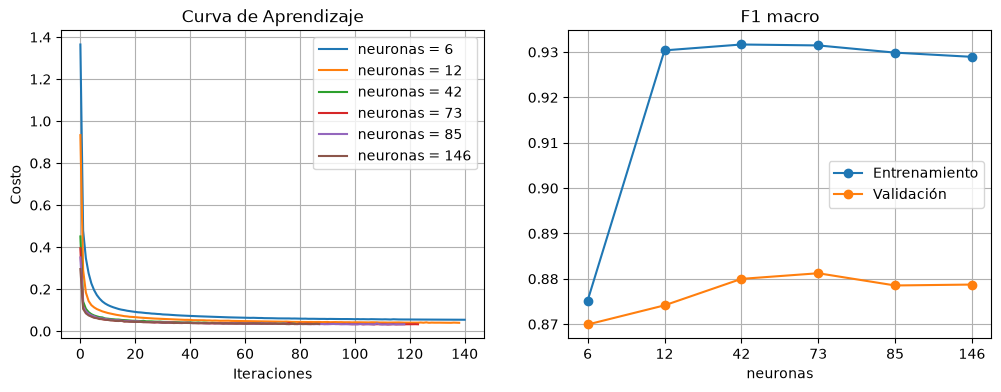

neuronas = 6: F1 entrenamiento = 0.8752 | F1 validación = 0.8699 | iteraciones = 141
neuronas = 12: F1 entrenamiento = 0.9304 | F1 validación = 0.8742 | iteraciones = 139
neuronas = 42: F1 entrenamiento = 0.9317 | F1 validación = 0.8800 | iteraciones = 79
neuronas = 73: F1 entrenamiento = 0.9315 | F1 validación = 0.8812 | iteraciones = 124
neuronas = 85: F1 entrenamiento = 0.9299 | F1 validación = 0.8785 | iteraciones = 119
neuronas = 146: F1 entrenamiento = 0.9289 | F1 validación = 0.8787 | iteraciones = 88


In [28]:
n_entradas = X_train.shape[1]   # 73
n_salidas = 12                  # tipos de ataque

neuronas = [n_salidas // 2, n_salidas, (n_entradas + n_salidas) // 2,
            n_entradas, n_entradas + n_salidas, 2 * n_entradas]

resultados = [entrenar_red(capas=(n,)) for n in neuronas]
graficar("neuronas", neuronas, resultados)


**Neuronas:** el F1 en validación aumenta hasta 73 neuronas (igual al número de entradas), con 0,8812, y después
baja ligeramente. Con 6 neuronas la red se queda corta (subajuste). 42 neuronas dan un resultado casi igual
(0,8800); se elige 73 por tener el mejor F1 en validación. Todas las curvas de costo convergen en pocas
iteraciones.


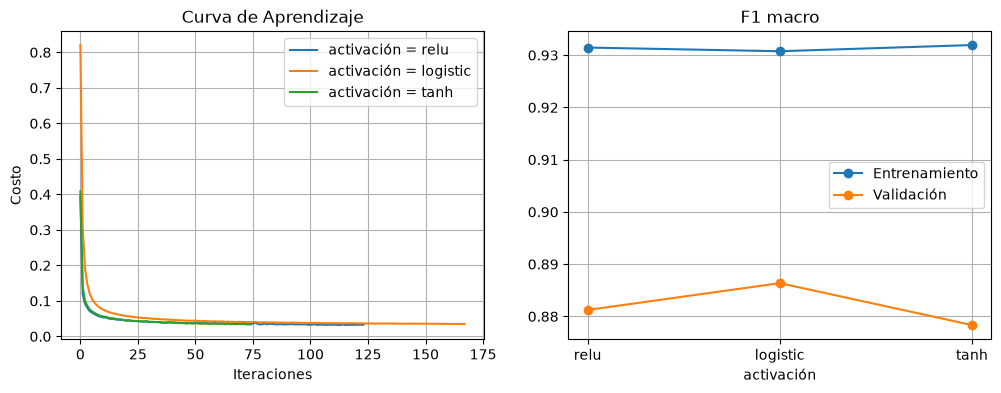

activación = relu: F1 entrenamiento = 0.9315 | F1 validación = 0.8812 | iteraciones = 124
activación = logistic: F1 entrenamiento = 0.9307 | F1 validación = 0.8864 | iteraciones = 168
activación = tanh: F1 entrenamiento = 0.9319 | F1 validación = 0.8783 | iteraciones = 75


In [30]:
mejor_neuronas = 73

activaciones = ["relu", "logistic", "tanh"]
resultados = [entrenar_red(capas=(mejor_neuronas,), activacion=a) for a in activaciones]
graficar("activación", activaciones, resultados)


**Activación:** la función logística (sigmoide) obtiene el mejor F1 en validación (0,8864), frente a ReLU
(0,8812) y tanh (0,8783), y es la que tiene menor diferencia entre entrenamiento y validación. Converge algo
más lento (168 iteraciones frente a 124 de ReLU), pero llega al mismo costo final. Las diferencias entre las
tres son pequeñas.


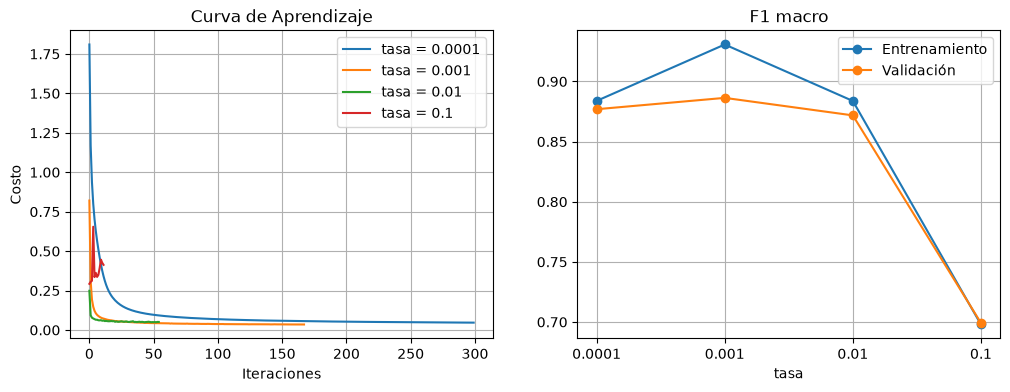

tasa = 0.0001: F1 entrenamiento = 0.8839 | F1 validación = 0.8769 | iteraciones = 300
tasa = 0.001: F1 entrenamiento = 0.9307 | F1 validación = 0.8864 | iteraciones = 168
tasa = 0.01: F1 entrenamiento = 0.8838 | F1 validación = 0.8718 | iteraciones = 55
tasa = 0.1: F1 entrenamiento = 0.6979 | F1 validación = 0.6992 | iteraciones = 12


In [31]:
mejor_activacion = "logistic"

tasas = [0.0001, 0.001, 0.01, 0.1]
resultados = [entrenar_red(capas=(mejor_neuronas,), activacion=mejor_activacion, tasa=t) for t in tasas]
graficar("tasa", tasas, resultados)


**Tasa de aprendizaje:** el mejor F1 en validación se obtiene con 0,001 (0,8864). Con 0,0001 la red aprende
demasiado lento y alcanza el límite de 300 iteraciones sin terminar de converger. Con 0,01 converge muy rápido
pero en una solución peor, y con 0,1 los pasos son tan grandes que el costo oscila y sube en lugar de bajar, y el
F1 cae a 0,70. Se observa la forma típica: una tasa muy baja no termina de aprender y una muy alta no se
estabiliza.


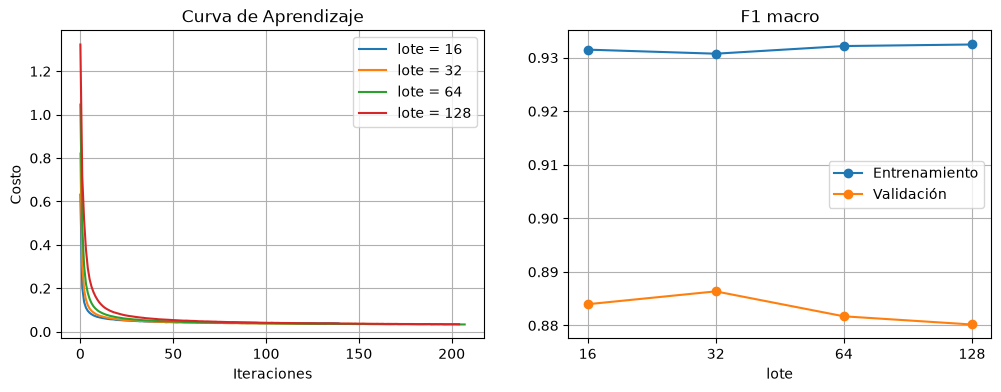

lote = 16: F1 entrenamiento = 0.9315 | F1 validación = 0.8840 | iteraciones = 140
lote = 32: F1 entrenamiento = 0.9307 | F1 validación = 0.8864 | iteraciones = 168
lote = 64: F1 entrenamiento = 0.9322 | F1 validación = 0.8817 | iteraciones = 208
lote = 128: F1 entrenamiento = 0.9325 | F1 validación = 0.8802 | iteraciones = 205


In [32]:
mejor_tasa = 0.001

lotes = [16, 32, 64, 128]
resultados = [entrenar_red(capas=(mejor_neuronas,), activacion=mejor_activacion, tasa=mejor_tasa, lote=l) for l in lotes]
graficar("lote", lotes, resultados)


**Tamaño de lote:** el mejor F1 en validación se obtiene con lotes de 32 (0,8864). Con lotes más grandes (64 y
128) la red hace menos actualizaciones por época, necesita más iteraciones para converger y generaliza algo peor
(0,8817 y 0,8802). Las diferencias son menores de un punto.


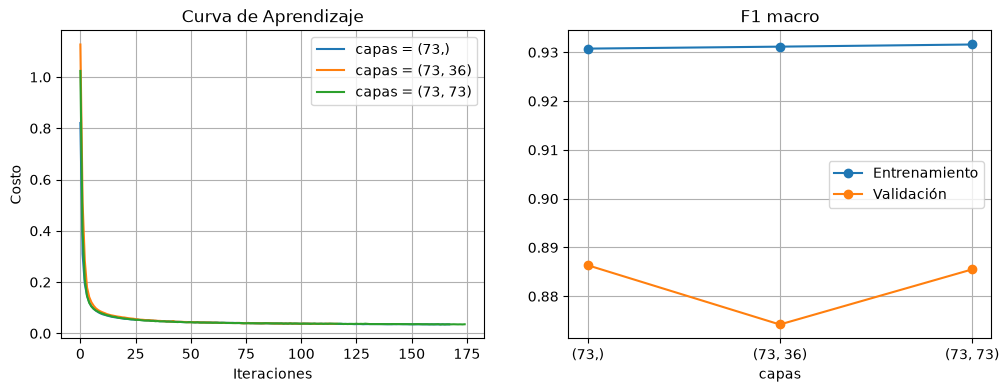

capas = (73,): F1 entrenamiento = 0.9307 | F1 validación = 0.8864 | iteraciones = 168
capas = (73, 36): F1 entrenamiento = 0.9312 | F1 validación = 0.8742 | iteraciones = 117
capas = (73, 73): F1 entrenamiento = 0.9316 | F1 validación = 0.8855 | iteraciones = 175


In [33]:
mejor_lote = 32

capas = [(73,), (73, 36), (73, 73)]
resultados = [entrenar_red(capas=c, activacion=mejor_activacion, tasa=mejor_tasa, lote=mejor_lote) for c in capas]
graficar("capas", capas, resultados)



**Capas ocultas:** añadir una segunda capa no mejora el resultado: (73, 73) obtiene 0,8855 y (73, 36) 0,8742,
frente a 0,8864 con una sola capa de 73 neuronas. Se mantiene una capa por ser el modelo más simple con el mejor
F1 en validación.


### Modelo final
Se entrena la red con los hiperparámetros elegidos: una capa oculta de 73 neuronas, activación logística, tasa de
aprendizaje 0,001 y lotes de 32. Se evalúa una sola vez en el conjunto de prueba.


In [34]:
mejor_capas = (73,)

f_mlp, f1_train, f1_val = entrenar_red(capas=mejor_capas, activacion=mejor_activacion,
                                       tasa=mejor_tasa, lote=mejor_lote)


In [35]:
# DESEMPEÑO EN ENTRENAMIENTO
Y_pred_train = f_mlp.predict(X_train)
print("ENTRENAMIENTO:")
print("accuracy:", accuracy_score(y_train, Y_pred_train))
print("precision:", precision_score(y_train, Y_pred_train, average="macro", zero_division=0))
print("recall:", recall_score(y_train, Y_pred_train, average="macro", zero_division=0))
print("f1:", f1_score(y_train, Y_pred_train, average="macro", zero_division=0))
print()

# DESEMPEÑO EN PRUEBA
Y_pred_test = f_mlp.predict(X_test)
print("PRUEBA:")
print("accuracy:", accuracy_score(y_test, Y_pred_test))
print("precision:", precision_score(y_test, Y_pred_test, average="macro", zero_division=0))
print("recall:", recall_score(y_test, Y_pred_test, average="macro", zero_division=0))
print("f1:", f1_score(y_test, Y_pred_test, average="macro", zero_division=0))


ENTRENAMIENTO:
accuracy: 0.9859062012714406
precision: 0.9859620863618693
recall: 0.9069723748843695
f1: 0.9307494926450189

PRUEBA:
accuracy: 0.9812534974818131
precision: 0.9019097367498156
recall: 0.8661580621129881
f1: 0.8818010489098219


In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_test, Y_pred_test, target_names=list(codigos), zero_division=0))


                            precision    recall  f1-score   support

            ARP_poisioning       0.97      0.98      0.97       794
            DDOS_Slowloris       1.00      0.79      0.88        80
             DOS_SYN_Hping       1.00      1.00      1.00         9
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      0.80      0.89         5
             NMAP_FIN_SCAN       0.00      0.00      0.00         1
         NMAP_OS_DETECTION       1.00      1.00      1.00       285
             NMAP_TCP_scan       1.00      1.00      1.00       150
             NMAP_UDP_SCAN       0.91      0.97      0.94       172
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       284
               Thing_Speak       0.98      0.98      0.98      1140
                Wipro_bulb       0.97      0.88      0.92        33

                  accuracy                           0.98      3574
                 macro avg       0.90      0.8

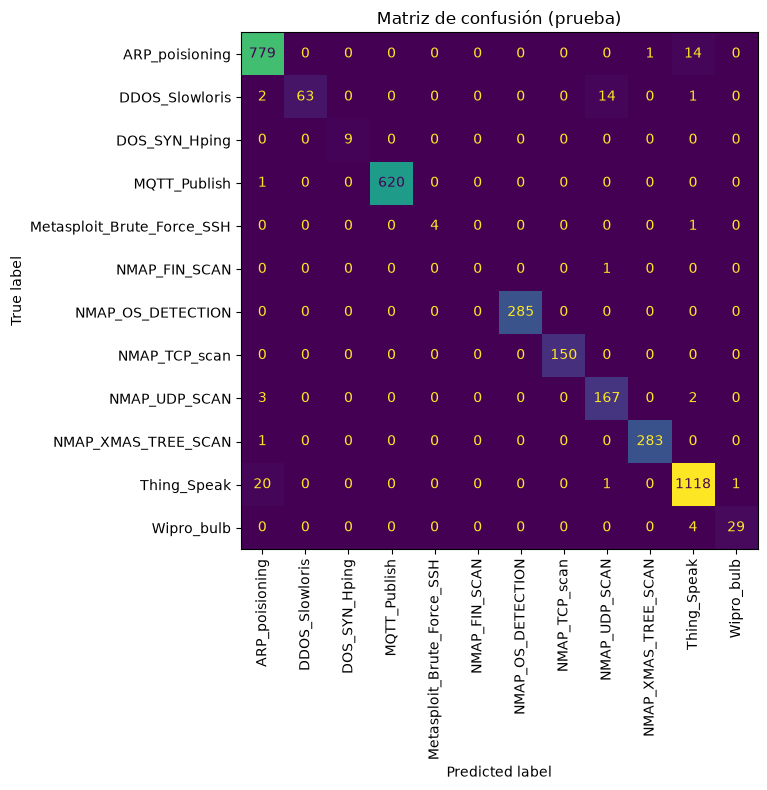

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, Y_pred_test, display_labels=list(codigos),
                                        xticks_rotation=90, colorbar=False, ax=ax)
ax.set_title("Matriz de confusión (prueba)")
plt.tight_layout()
plt.show()


### Conclusiones del modelo final
El modelo obtiene en prueba un accuracy de 0,981 y un F1 macro de 0,882. No hay sobreajuste: el F1 por clase en
entrenamiento y en prueba es prácticamente igual (por ejemplo, 0,98 y 0,97 en ARP_poisioning, o 0,90 y 0,88 en
DDOS_Slowloris), y ninguna fila de prueba es idéntica a una de entrenamiento.

Cinco clases se clasifican perfectamente (DOS_SYN_Hping, MQTT_Publish, NMAP_OS_DETECTION, NMAP_TCP_scan y
NMAP_XMAS_TREE_SCAN) porque son ataques generados por herramientas automáticas con una firma muy clara: por
ejemplo, todo el tráfico con servicio `mqtt` es MQTT_Publish y toda conexión con la bandera URG es
NMAP_XMAS_TREE_SCAN.

Los errores se concentran en clases con tráfico parecido: DDOS_Slowloris se confunde con NMAP_UDP_SCAN (ambas
usan `http`) y Thing_Speak con ARP_poisioning (ambas usan `dns` y `ssl`). NMAP_FIN_SCAN no se detecta: tras
eliminar los duplicados solo quedan 5 registros distintos (3 en entrenamiento y 1 en prueba), insuficientes para
aprender la clase. Esta es la principal limitación del modelo. Metasploit_Brute_Force_SSH también tiene pocos
registros (5 en prueba), por lo que su métrica es poco estable.